In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [20]:
df = pd.read_csv('D:/Hareshan/ICT class/Data sci/Project/Project 18/Bestsellers with categories.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 550 entries, 0 to 549
Data columns (total 7 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   Name         550 non-null    str    
 1   Author       550 non-null    str    
 2   User Rating  550 non-null    float64
 3   Reviews      550 non-null    int64  
 4   Price        550 non-null    int64  
 5   Year         550 non-null    int64  
 6   Genre        550 non-null    str    
dtypes: float64(1), int64(3), str(3)
memory usage: 30.2 KB


In [21]:
df.isnull().sum()

Name           0
Author         0
User Rating    0
Reviews        0
Price          0
Year           0
Genre          0
dtype: int64

In [22]:
genre_frequency = df["Genre"].value_counts()
print(genre_frequency)

Genre
Non Fiction    310
Fiction        240
Name: count, dtype: int64


In [23]:
genre_order = ["Fiction", "Non Fiction"]
df["Genre"] = pd.Categorical(
    df["Genre"],
    categories=genre_order,
    ordered=True
)

median_index = np.median(df["Genre"].cat.codes)
median_genre = genre_order[int(median_index)]


In [24]:
print(median_index)

1.0


In [25]:
print(median_genre)

Non Fiction


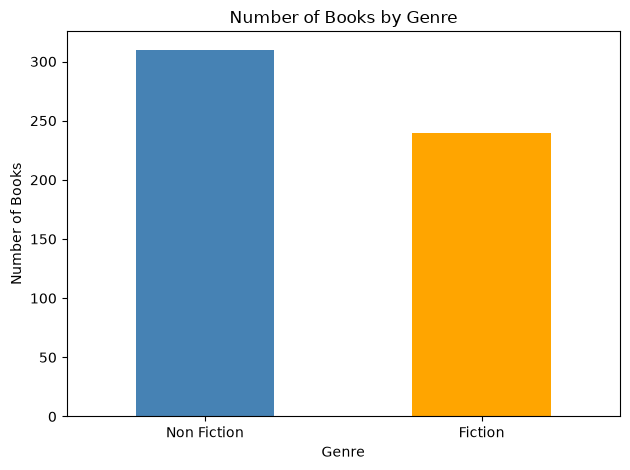

In [26]:
genre_frequency.plot(kind="bar", color=["steelblue", "orange"])
plt.title("Number of Books by Genre")
plt.xlabel("Genre")
plt.ylabel("Number of Books")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

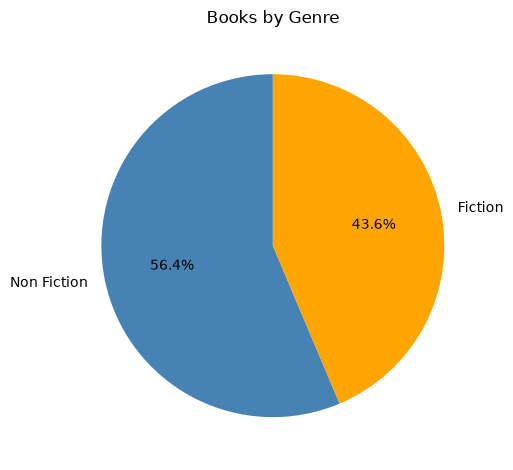

In [27]:
genre_frequency.plot(
    kind="pie",
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "orange"]
)
plt.title("Books by Genre")
plt.tight_layout()
plt.show()

In [28]:
from sklearn.preprocessing import StandardScaler
numeric_df = df.select_dtypes(include="number").copy()

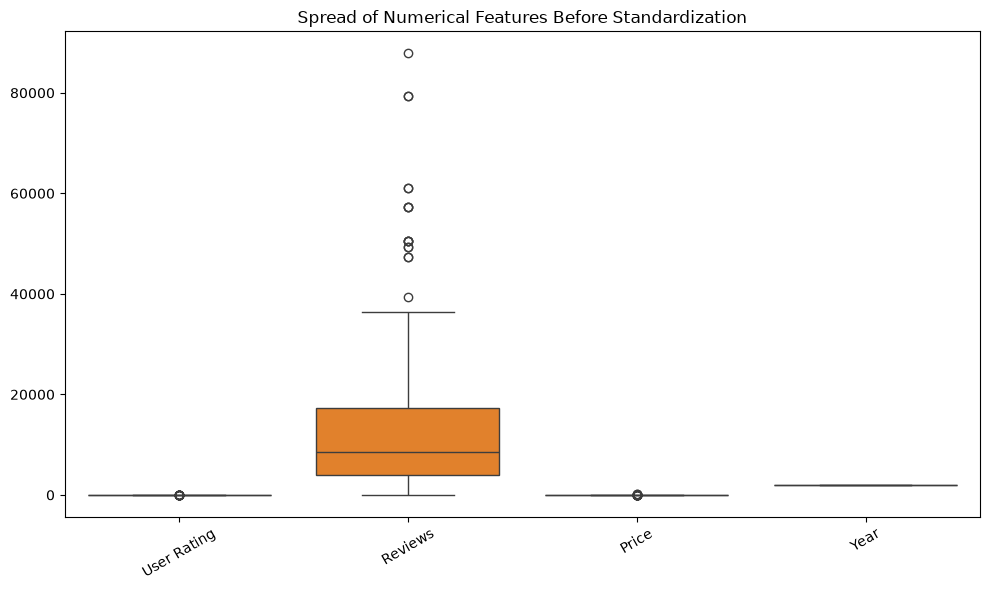

In [29]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=numeric_df)
plt.title("Spread of Numerical Features Before Standardization")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [30]:
scaler = StandardScaler()
standardized_df = pd.DataFrame(
    scaler.fit_transform(numeric_df),
    columns=numeric_df.columns,
    index=numeric_df.index
)

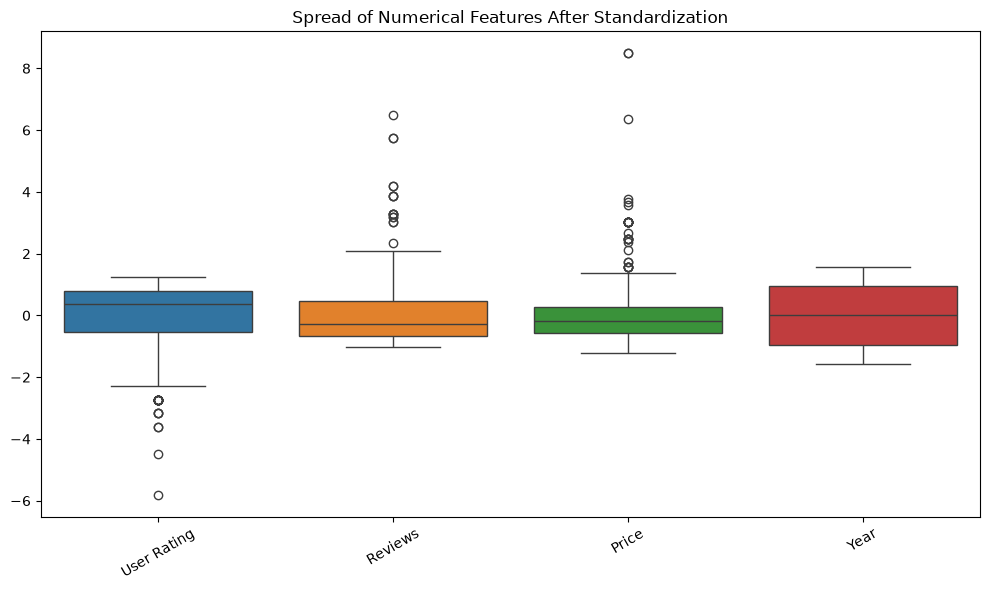

In [31]:
plt.figure(figsize=(10, 6))
sns.boxplot(data=standardized_df)
plt.title("Spread of Numerical Features After Standardization")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()